In [2]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange, repeat
from matplotlib import pyplot as plt

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp
from torch.autograd import grad, Variable

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.uoro import UOROModel
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.my_uoro import UORO
from memoryPerceiver.memory_perceiver.core.my_rtrl import RTRL, RTRL_partial

%load_ext autoreload
%autoreload 2
device = 'cuda:1'

In [3]:
import numpy as np


def one_hot_encode(value, n_class):
    vec = np.zeros([n_class])
    vec[value] = 1
    return vec


def one_hot_decode(encoded_seq):
    return [np.argmax(vector) for vector in encoded_seq]


def get_an_bn_array(num_data, k, l):
    """
    modified from https://github.com/petered/uoro-demo
    """
    x = np.zeros([num_data], dtype=int)

    i = 0
    while i < num_data:
        n = np.random.randint(low=k, high=l+1)
        x[i:i+n] = 1
        x[i+n+1: i+2*n+1] = 2
        i += 2*n + 2
    return x


def generate_anbn_data(num_data, k=1, l=4, num_class=3):
    X_arr = get_an_bn_array(num_data+1, k, l)
    X = np.zeros([1, num_data, num_class])
    Y = np.zeros([1, num_data, num_class])
    for i in range(num_data):
        X[0, i] = one_hot_encode(X_arr[i], num_class)
        Y[0, i] = one_hot_encode(X_arr[i+1], num_class)
    return X, Y


X, Y = generate_anbn_data(10000, k=10, l=20, num_class=3)
X = torch.from_numpy(X).float().to(device)
Y = torch.from_numpy(np.argmax(Y, axis=2)).long().to(device)

In [101]:
# RNN
loss_all=[]
l = []
loss_acc=0
input_size=3
hidden_size=10
output_size=3
old_s = torch.zeros(size=[1, 1, hidden_size], requires_grad=True, device=device)
criterion=torch.nn.CrossEntropyLoss()
model=SimpleRNN(3,hidden_size,3).to(device)
uoro_grad = UORO(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
# UORO
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)

        y, new_s = model(x_t, old_s)
        loss=criterion(y[0], y_t)
        uoro_grad.step(model, x_t, new_s, old_s, loss)
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%1000 == 0:
            print(loss_acc)
            loss_acc=0

In [ ]:
# BPTT
loss=torch.tensor(0.0, device=device)
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)

        y, new_s = model(x_t, old_s)
        loss+=criterion(y.squeeze(0), y_t)
        # uoro_grad.step(model, x_t, new_s, old_s, loss)
        if iter_id % 5 == 0:
            optimizer.zero_grad()
            loss.backward()
            old_s = new_s.detach().clone().requires_grad_(True)
            optimizer.step()
            loss_all.append(loss.item()/5)
            loss_acc += loss.item()
            loss=torch.tensor(0.0, device=device)
        else:
            old_s = new_s.clone() #.detach().clone()  #.detach().clone().requires_grad_(True)
        
        if iter_id%100 == 0:
            print(loss_acc)
            loss_acc=0

In [4]:
# Mem Perceiver
from memoryPerceiver.memory_perceiver.main.configuration import cf
loss_all = []
loss_acc=0
criterion=torch.nn.CrossEntropyLoss()
cf.body_outputs['critic']=3 # agent.py -> values = rearrange(output['critic'], 'b () d -> b d')
cf.shared=True 
cf.dim_observations=3
cf.num_envs=1
cf.depth=1
cf.query_dim=512
cf.nb_latents=2
cf.nb_latents_mem=1024
cf.latent_dim_head=2
model=create_agent(cf, device)
old_s = create_memories(model.actor, cf.num_envs, device=device)
mem_dim = old_s.shape
old_s = rearrange(old_s, 'b d l h -> (b d l h)')
# uoro_grad = UORO(model, epsilon_perturbation=1e-7)
for name, p in model.named_parameters():
    if name.startswith('actor.state_'):
        if name.startswith('actor.state_cross_attn.fn'):
            p.requires_grad = True
        else:
            p.requires_grad = False
rtrl_grad = RTRL_partial(model, param_state_filter='actor.state_', 
                         chunks=16, slice_indexes=list(range(524288-4096, 524288)))
# rtrl_grad = RTRL(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model.train()
dummy0=torch.zeros(cf.num_envs, 1, cf.dim_actions, device=device)
states = {}

In [4]:
print(rtrl_grad.d_state_d_theta.size())
rtrl_grad.d_state_d_theta.count_nonzero() / (rtrl_grad.d_state_d_theta.shape[0] * rtrl_grad.d_state_d_theta.shape[1])

AttributeError: 'NoneType' object has no attribute 'size'

In [ ]:
# params = dict(model.named_parameters())
from torch.func import vmap, jacrev, jacfwd, functional_call
from torch.autograd import grad

params = {}
for name, p in model.named_parameters():
    if p.requires_grad and name.startswith('actor.state_'):
        params[name]=p.detach()
slice_indexes = list(range(524288-65536, 524288))
old_s_sliced = old_s[slice_indexes].detach()

def fmodel(params, old_s_sliced): #functional version of model
    # with torch.no_grad():
    old_s_clone = old_s.clone()
    old_s_clone[slice_indexes] = old_s_sliced
    _, _, _, new_s = functional_call(model, params, (states, old_s_clone), {'old_actions':dummy0, 'flattened_mem':mem_dim})
    return new_s[:512]


# result = vmap(jacrev(fmodel, argnums=(0)), in_dims=(None,0))(params, old_s)
%time new_s = fmodel(params, old_s_sliced)
_, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)


# %time jac0=[grad(outputs=o, inputs=param_list, allow_unused=True, retain_graph=True)for o in new_s]
# %time jac=jacrev(fmodel, argnums=(1))(params, old_s)
# with torch.no_grad():
def compute_jac(argnum):
    jac=jacrev(fmodel, argnums=(argnum))(params, old_s_sliced)
    return jac
jac = compute_jac(1)
# jac=jac.detach()
# new_s = new_s.detach()
#%time jac=jacfwd(fmodel, argnums=(1))(params, old_s)
# %time jac = vmap(jacrev(fmodel, argnums=(0)), in_dims=(None,0))(params, old_s)
# for k, j in jac.items():
#     if torch.count_nonzero(j)>0 :
#         print(k,j.shape)

In [4]:
torch.cuda.empty_cache() 

In [5]:
torch.cuda.mem_get_info(0)[0] / (1e9)

16.611999744

In [9]:
#torch.sparse.check_sparse_tensor_invariants.enable()

In [10]:
# RTRL
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:   , iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)
        _, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)
        # y = torch.nn.functional.softmax(y)
        loss=criterion(y, y_t)
        try:
            rtrl_grad.step(model, states, old_s, loss, old_actions=dummy0, flattened_mem=mem_dim)
        except Exception as e:
            raise e
        # loss.backward()
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%1 == 0:
            print(loss_acc)
            loss_acc=0

0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
76.02008056640625
74.47528839111328


In [7]:
torch.eye(5).to_sparse_csr()

tensor(crow_indices=tensor([0, 1, 2, 3, 4, 5]),
       col_indices=tensor([0, 1, 2, 3, 4]),
       values=tensor([1., 1., 1., 1., 1.]), size=(5, 5), nnz=5,
       layout=torch.sparse_csr)

In [13]:
new_s

RuntimeError: CUDA error: an illegal memory access was encountered
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1.
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [12]:
old_s = new_s.detach().clone().requires_grad_(True)

RuntimeError: CUDA error: an illegal memory access was encountered
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1.
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [5]:
new_s

RuntimeError: CUDA error: an illegal memory access was encountered
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1.
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [25]:
torch.cuda.mem_get_info()[0] * 10e-9

157.83624704

In [56]:
import torch
device='cuda:0'
# torch.sparse_bsc_tensor([0],[],[[[]]], size=(2,3), device=device).to_dense()
crow_indices = torch.tensor([0, 2, 4, 4])
col_indices = torch.tensor([0, 1, 0, 1])
values = torch.tensor([0, 1, 6, 7])
bsc = torch.sparse_csr_tensor(crow_indices, col_indices, values, size=(4,4), dtype=torch.float64, device=device)

In [55]:
torch.sparse_csr_tensor([0],[],[], size=(2,3), device=device).to_dense()

tensor([[0., 0., 0.],
        [0., 0., 0.]], device='cuda:0')

In [54]:
def cat_CSR_rows(csr_list):
    device = csr_list[0].device
    dtype = csr_list[0].dtype
    rows = 0
    cols = csr_list[0].size()[1]
    crow_indices_list, col_indices_list, values_list = [], [], []
    ccol_sum = 0
    for i, csr in enumerate(csr_list):
        rows += csr.size()[0]
        crow_indices_tmp = csr.crow_indices()
        crow_indices_list.append(crow_indices_tmp+ccol_sum)
        ccol_sum += crow_indices_tmp[-1]
        col_indices_list.append(csr.col_indices())
        values_list.append(csr.values())
    crow_indices = torch.cat(crow_indices_list)
    col_indices = torch.cat(col_indices_list)
    values = torch.cat(values_list)
    return torch.sparse_csr_tensor(crow_indices, col_indices, values, size=(rows, cols), device=device, dtype=dtype)


In [58]:
cat_CSR_rows([bsc]).to_dense()

tensor([[0., 1., 0., 0.],
        [6., 7., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]], device='cuda:0', dtype=torch.float64)

In [47]:
ccol_indices = torch.tensor([0, 2, 2,4])
row_indices = torch.tensor([0, 1,0,1])
values = torch.tensor([[[0, 1], [6, 7]],
                        [[3, 4], [9, 10]], 
                        [[0, 1], [6, 7]],
                        [[3, 4], [9, 10]]])
bsc = torch.sparse_bsc_tensor(ccol_indices, row_indices, values, size=(4,8), dtype=torch.float64)

In [ ]:
# BPTT
loss=torch.tensor(0.0, device=device)
horizon=10
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)

        _, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)
        loss+=criterion(y, y_t)
        if iter_id % horizon == 0:
            optimizer.zero_grad()
            loss.backward()
            old_s = new_s.detach().clone().requires_grad_(True)
            optimizer.step()
            loss_all.append(loss.item()/horizon)
            loss_acc += loss.item()
            loss=torch.tensor(0.0, device=device)
        else:
            old_s = new_s.clone() #.detach().clone()  #.detach().clone().requires_grad_(True)
        
        if iter_id%1000 == 0:
            print(loss_acc)
            loss_acc=0

In [ ]:
# UORO
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:   , iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)
        _, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)
        # y = torch.nn.functional.softmax(y)
        loss=criterion(y, y_t)
        uoro_grad.step(model, states, new_s, old_s, loss, old_actions=dummy0, flattened_mem=mem_dim)
        # loss.backward()
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%1000 == 0:
            print(loss_acc)
            loss_acc=0

In [93]:
for param_group in optimizer.param_groups:
    param_group['lr'] = 1e-4

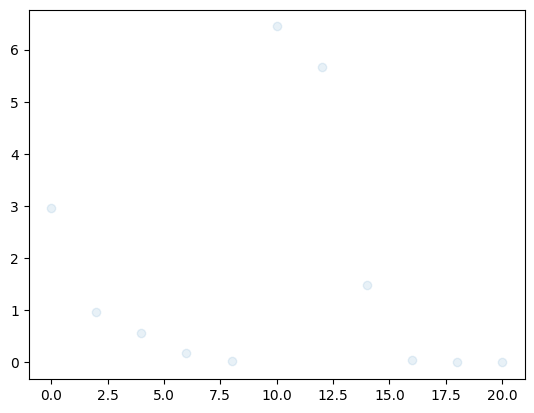

In [18]:
# < 0.68 and close to 0.25 RNN
# plt.plot(loss_all)
# loss_all = [x for x in loss_all if x <2]
h=2
#plt.plot([sum(loss_all[i: i+h])/h for i in range(0,len(loss_all),h)], alpha=0.5)
plt.scatter(x=list(range(0,len(loss_all),h)) , y=[sum(loss_all[i: i+h])/h for i in range(0,len(loss_all),h)], alpha=0.1)
plt.show()

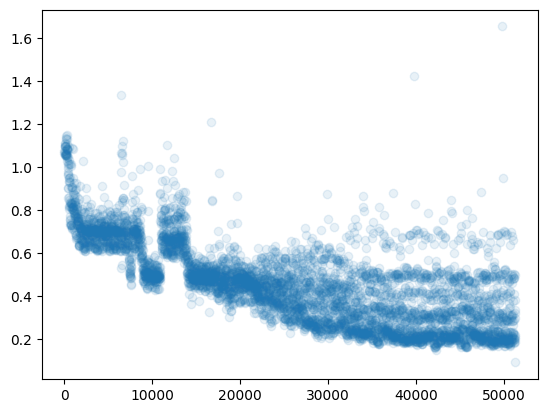

In [98]:
# < 0.68 and close to 0.25 RNN
# plt.plot(loss_all)
h=10
#plt.plot([sum(loss_all[i: i+h])/h for i in range(0,len(loss_all),h)], alpha=0.5)
plt.scatter(x=list(range(0,len(loss_all),h)) , y=[sum(loss_all[i: i+h])/h for i in range(0,len(loss_all),h)], alpha=0.1)
plt.show()

In [ ]:
torch.tensor(loss_all)[:5000].mean()